## PR 2 — Adult Income Classification

---------------------------------------------------------------------------------------------------------------------------------------------------

### Task 1: Data Loading, Cleaning & Exploratory Data Analysis

1.1 Load and inspect the dataset

In [149]:
#All Libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn import model_selection, metrics
import tensorflow as tf


In [98]:
df = pd.read_csv('D:\Deep learning\Pr.2\data_adult.csv')

<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:1: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Admin\AppData\Local\Temp\ipykernel_29252\3451410564.py:1: SyntaxWarning: invalid escape sequence '\D'
  df = pd.read_csv('D:\Deep learning\Pr.2\data_adult.csv')


In [99]:
print(df.shape)
print("--------------------------------------------------------------------------")
print(df.dtypes)
print("--------------------------------------------------------------------------")
print(df.head())

(48842, 15)
--------------------------------------------------------------------------
age                 int64
workclass          object
fnlwgt              int64
education          object
educational-num     int64
marital-status     object
occupation         object
relationship       object
race               object
gender             object
capital-gain        int64
capital-loss        int64
hours-per-week      int64
native-country     object
income             object
dtype: object
--------------------------------------------------------------------------
   age  workclass  fnlwgt     education  educational-num      marital-status  \
0   25    Private  226802          11th                7       Never-married   
1   38    Private   89814       HS-grad                9  Married-civ-spouse   
2   28  Local-gov  336951    Assoc-acdm               12  Married-civ-spouse   
3   44    Private  160323  Some-college               10  Married-civ-spouse   
4   18          ?  103497  Some-co

In [100]:
for col in df.select_dtypes('object'):
    df[col] = df[col].str.strip()

1.2 Handle missing values

In [101]:
df.replace('?', np.nan, inplace=True)

In [102]:
df.isnull().sum()

age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64

In [103]:
df.dropna(inplace=True)

we have to dropdown the missing values rows because infuture while doing traning this can cause outliers and errors 

In [104]:
df_copy = df #for graph purpose only

1.3 Drop redundant columns

In [105]:
df.drop(columns=['fnlwgt','education'], inplace=True)

1.4 Encode the target

In [106]:
df['income'] = (df['income'] == '>50K').astype(int)

In [107]:
print(df['income'].value_counts())

income
0    34014
1    11208
Name: count, dtype: int64


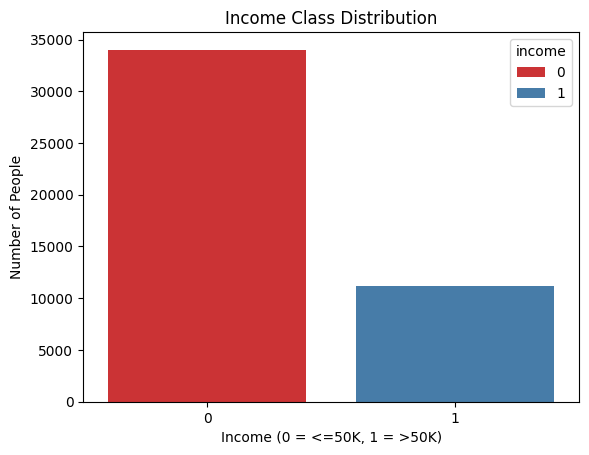

In [108]:
sns.countplot(x='income', data=df, hue='income', palette='Set1')
plt.title('Income Class Distribution')
plt.xlabel('Income (0 = <=50K, 1 = >50K)')
plt.ylabel('Number of People')
plt.show()

1.5 Exploratory visualisations

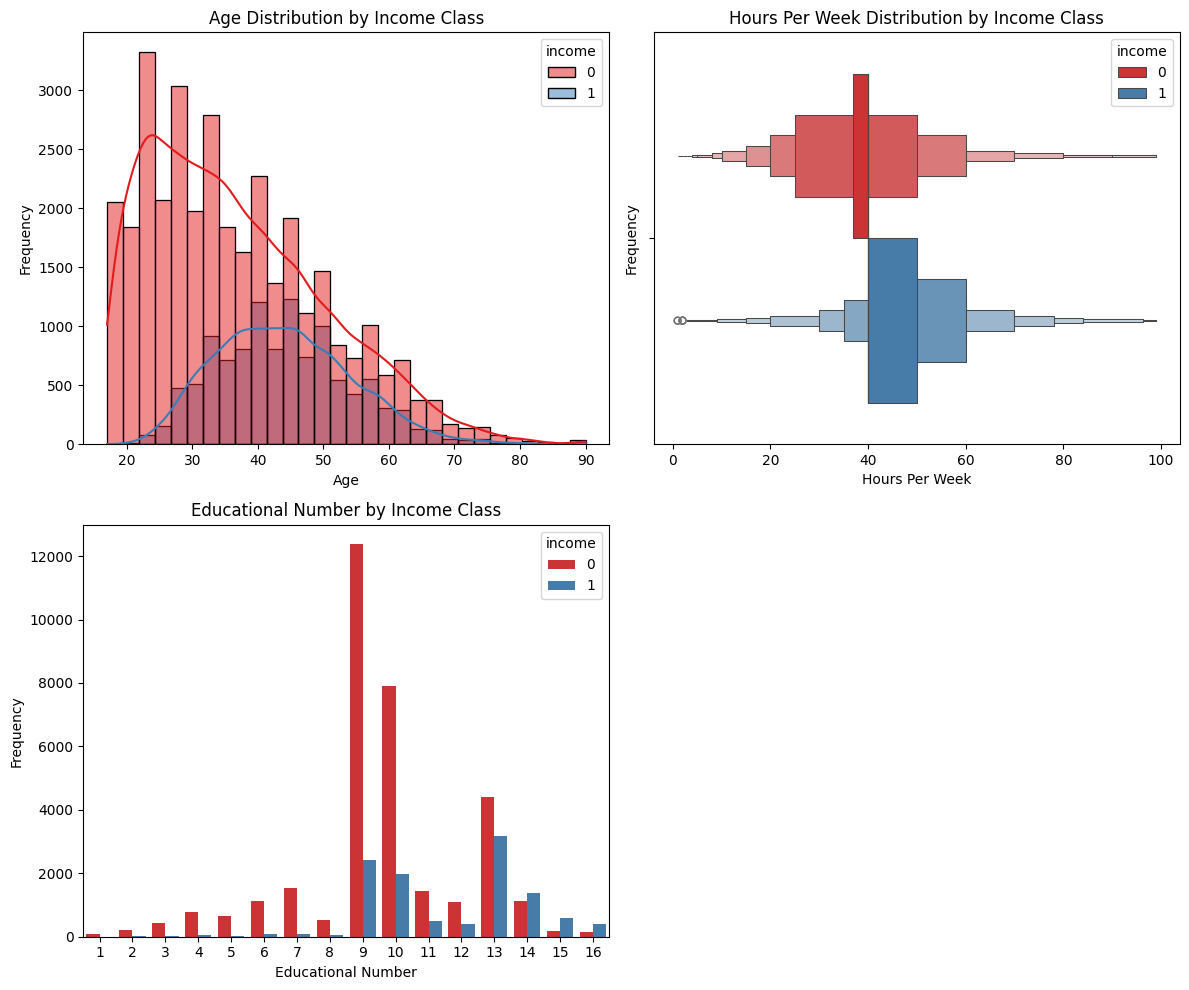

In [109]:
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)

sns.histplot(x=df['age'], hue=df['income'], palette='Set1', bins=30, kde=True)
plt.title('Age Distribution by Income Class')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.subplot(2, 2, 2)

sns.boxenplot(x=df['hours-per-week'], hue=df['income'], palette='Set1')
plt.title('Hours Per Week Distribution by Income Class')
plt.xlabel('Hours Per Week')
plt.ylabel('Frequency')

plt.subplot(2, 2, 3)

sns.countplot(x=df_copy['educational-num'], hue=df['income'], palette='Set1')
plt.title('Educational Number by Income Class')
plt.xlabel('Educational Number')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


EDA Observations

- Most individuals earning <=50K are concentrated in the younger age groups, while the >50K group is more concentrated around middle age.
- Individuals earning >50K generally work more hours per week than those earning <=50K.
- Higher education levels show a greater representation of individuals earning >50K.

1.6 Encode categoricals & scale numerics

In [110]:
X = df.drop('income', axis=1)
y = df['income']

In [111]:
X = pd.get_dummies(X, drop_first=True)

In [113]:
columns_to_scale = ['age', 'capital-gain', 'capital-loss', 'hours-per-week']

for col in columns_to_scale:
    scaler = StandardScaler()
    X[col] = scaler.fit_transform(X[[col]])

In [120]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [122]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (36177, 80)
X_test shape: (9045, 80)
y_train shape: (36177,)
y_test shape: (9045,)


---------------------------------------------------------------------------------------------------------------------------------------------------

### Task 2: MLP Architecture — Baseline ANN

2.1 Define the reusable build_ann() function

In [134]:
input_dim = X_train.shape[1]

In [135]:
def build_ann(input_dim, hidden_units=128, activation='relu',
              initializer='glorot_uniform',
              use_batch_norm=False,
              optimizer='adam',
              loss='binary_crossentropy'):

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(hidden_units, activation=activation, kernel_initializer=initializer),
        tf.keras.layers.Dense(64, activation=activation, kernel_initializer=initializer),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )

    return model

2.2 Baseline ANN architecture

In [136]:
model = build_ann(input_dim=input_dim)

In [138]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,069 (219.02 KB)

 Trainable params: 18,689 (73.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 37,380 (146.02 KB)

2.3 Train the baseline

In [139]:
model_base = build_ann(input_dim=X_train.shape[1])
history_base = model_base.fit(X_train, y_train, epochs=50, batch_size=64, validation_split=0.1, verbose=1 )

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 998us/step - accuracy: 0.8365 - loss: 0.3488 - val_accuracy: 0.8513 - val_loss: 0.3251
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 824us/step - accuracy: 0.8515 - loss: 0.3200 - val_accuracy: 0.8519 - val_loss: 0.3215
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 833us/step - accuracy: 0.8513 - loss: 0.3165 - val_accuracy: 0.8557 - val_loss: 0.3206
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 825us/step - accuracy: 0.8521 - loss: 0.3138 - val_accuracy: 0.8538 - val_loss: 0.3196
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 849us/step - accuracy: 0.8539 - loss: 0.3104 - val_accuracy: 0.8543 - val_loss: 0.3198
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 822us/step - accuracy: 0.8555 - loss: 0.3083 - val_accuracy: 0.8543 - val_loss: 0.3256
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 815us/step - accuracy: 0.8569 - loss: 0.3056 - val_accuracy: 0.8507 - val_loss: 0.3185
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 823us/step - accuracy: 0.8575 - loss: 0.3045 - 

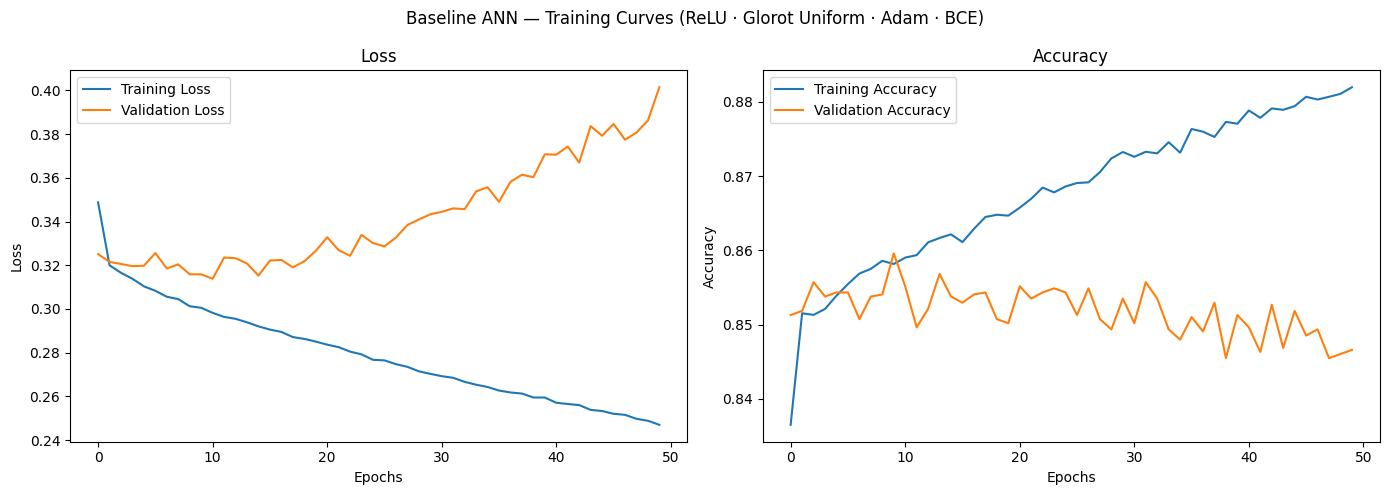

In [141]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_base.history['loss'], label='Training Loss')
plt.plot(history_base.history['val_loss'], label='Validation Loss')
plt.title('Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_base.history['accuracy'], label='Training Accuracy')
plt.plot(history_base.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.suptitle('Baseline ANN — Training Curves (ReLU · Glorot Uniform · Adam · BCE)')
plt.tight_layout()
plt.show()

2.4 Evaluate the baseline with full metrics

In [148]:
y_pred_prob = model_base.predict(X_test).flatten()
y_pred = (y_pred_prob > 0.5).astype(int)

283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 417us/step


In [152]:
print(metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.92      0.90      6803
           1       0.72      0.61      0.66      2242

    accuracy                           0.84      9045
   macro avg       0.80      0.77      0.78      9045
weighted avg       0.84      0.84      0.84      9045



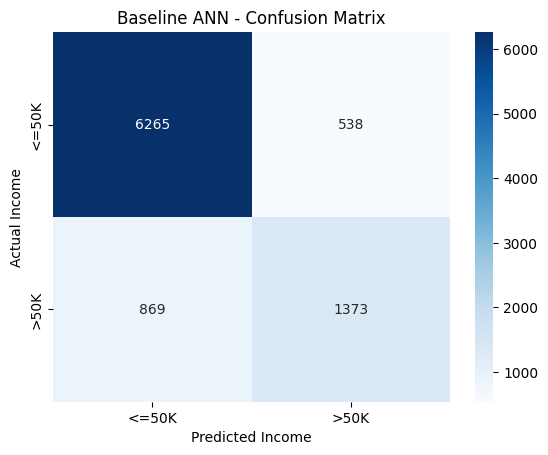

In [154]:
cm = metrics.confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['<=50K', '>50K'], yticklabels=['<=50K', '>50K'] )

plt.xlabel('Predicted Income')
plt.ylabel('Actual Income')
plt.title('Baseline ANN - Confusion Matrix')
plt.show()

---------------------------------------------------------------------------------------------------------------------------------------------------

### Task 3: Activation Functions — Comparison Experiment

3.1 Train 4 models with different hidden activations

In [156]:
model_relu = build_ann(input_dim=X_train.shape[1], activation='relu' )

history_relu = model_relu.fit(X_train, y_train, epochs=50, batch_size=64, validation_split=0.1, verbose=1 )

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 992us/step - accuracy: 0.8321 - loss: 0.3554 - val_accuracy: 0.8463 - val_loss: 0.3332
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 838us/step - accuracy: 0.8484 - loss: 0.3217 - val_accuracy: 0.8477 - val_loss: 0.3223
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 973us/step - accuracy: 0.8513 - loss: 0.3177 - val_accuracy: 0.8519 - val_loss: 0.3218
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 907us/step - accuracy: 0.8519 - loss: 0.3148 - val_accuracy: 0.8530 - val_loss: 0.3265
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 908us/step - accuracy: 0.8535 - loss: 0.3128 - val_accuracy: 0.8527 - val_loss: 0.3191
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 923us/step - accuracy: 0.8526 - loss: 0.3104 - val_accuracy: 0.8560 - val_loss: 0.3207
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 912us/step - accuracy: 0.8542 - loss: 0.3089 - val_accuracy: 0.8538 - val_loss: 0.3157
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 917us/step - accuracy: 0.8564 - loss: 0.3056 - 

In [157]:
model_tanh = build_ann(input_dim=X_train.shape[1], activation='tanh' )

history_tanh = model_tanh.fit(X_train, y_train, epochs=50, batch_size=64, validation_split=0.1, verbose=1 )

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8400 - loss: 0.3424 - val_accuracy: 0.8413 - val_loss: 0.3379
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 866us/step - accuracy: 0.8481 - loss: 0.3245 - val_accuracy: 0.8521 - val_loss: 0.3242
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 866us/step - accuracy: 0.8507 - loss: 0.3186 - val_accuracy: 0.8483 - val_loss: 0.3293
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 872us/step - accuracy: 0.8496 - loss: 0.3175 - val_accuracy: 0.8541 - val_loss: 0.3213
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 869us/step - accuracy: 0.8522 - loss: 0.3140 - val_accuracy: 0.8521 - val_loss: 0.3213
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 872us/step - accuracy: 0.8517 - loss: 0.3146 - val_accuracy: 0.8516 - val_loss: 0.3199
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 864us/step - accuracy: 0.8534 - loss: 0.3109 - val_accuracy: 0.8469 - val_loss: 0.3238
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 869us/step - accuracy: 0.8537 - loss: 0.3098 - va

In [158]:
model_sigmoid = build_ann(input_dim=X_train.shape[1], activation='sigmoid' )

history_sigmoid = model_sigmoid.fit(X_train, y_train, epochs=50, batch_size=64, validation_split=0.1, verbose=1 )

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 999us/step - accuracy: 0.8192 - loss: 0.3834 - val_accuracy: 0.8452 - val_loss: 0.3363
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 843us/step - accuracy: 0.8457 - loss: 0.3293 - val_accuracy: 0.8447 - val_loss: 0.3345
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 849us/step - accuracy: 0.8479 - loss: 0.3251 - val_accuracy: 0.8441 - val_loss: 0.3351
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 989us/step - accuracy: 0.8475 - loss: 0.3243 - val_accuracy: 0.8463 - val_loss: 0.3332
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 919us/step - accuracy: 0.8502 - loss: 0.3215 - val_accuracy: 0.8510 - val_loss: 0.3250
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 922us/step - accuracy: 0.8491 - loss: 0.3205 - val_accuracy: 0.8516 - val_loss: 0.3242
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 836us/step - accuracy: 0.8501 - loss: 0.3195 - val_accuracy: 0.8507 - val_loss: 0.3236
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 835us/step - accuracy: 0.8510 - loss: 0.3181 - 

In [159]:
model_elu = build_ann(input_dim=X_train.shape[1], activation='elu')

history_elu = model_elu.fit(X_train, y_train, epochs=50, batch_size=64, validation_split=0.1, verbose=1)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8405 - loss: 0.3429 - val_accuracy: 0.8472 - val_loss: 0.3273
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 839us/step - accuracy: 0.8489 - loss: 0.3254 - val_accuracy: 0.8394 - val_loss: 0.3317
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 854us/step - accuracy: 0.8496 - loss: 0.3219 - val_accuracy: 0.8496 - val_loss: 0.3225
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 836us/step - accuracy: 0.8491 - loss: 0.3191 - val_accuracy: 0.8524 - val_loss: 0.3240
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 850us/step - accuracy: 0.8529 - loss: 0.3170 - val_accuracy: 0.8472 - val_loss: 0.3228
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 847us/step - accuracy: 0.8520 - loss: 0.3160 - val_accuracy: 0.8449 - val_loss: 0.3310
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 848us/step - accuracy: 0.8505 - loss: 0.3160 - val_accuracy: 0.8499 - val_loss: 0.3271
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 844us/step - accuracy: 0.8517 - loss: 0.3150 - va

3.2 Activation comparison — 4-panel plot

In [161]:
y_pred_relu = (model_relu.predict(X_test).flatten() > 0.5).astype(int)
y_pred_tanh = (model_tanh.predict(X_test).flatten() > 0.5).astype(int)
y_pred_sigmoid = (model_sigmoid.predict(X_test).flatten() > 0.5).astype(int)
y_pred_elu = (model_elu.predict(X_test).flatten() > 0.5).astype(int)

f1_relu = metrics.f1_score(y_test, y_pred_relu)
f1_tanh = metrics.f1_score(y_test, y_pred_tanh)
f1_sigmoid = metrics.f1_score(y_test, y_pred_sigmoid)
f1_elu = metrics.f1_score(y_test, y_pred_elu)

283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 440us/step
283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 422us/step
283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 401us/step
283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 399us/step


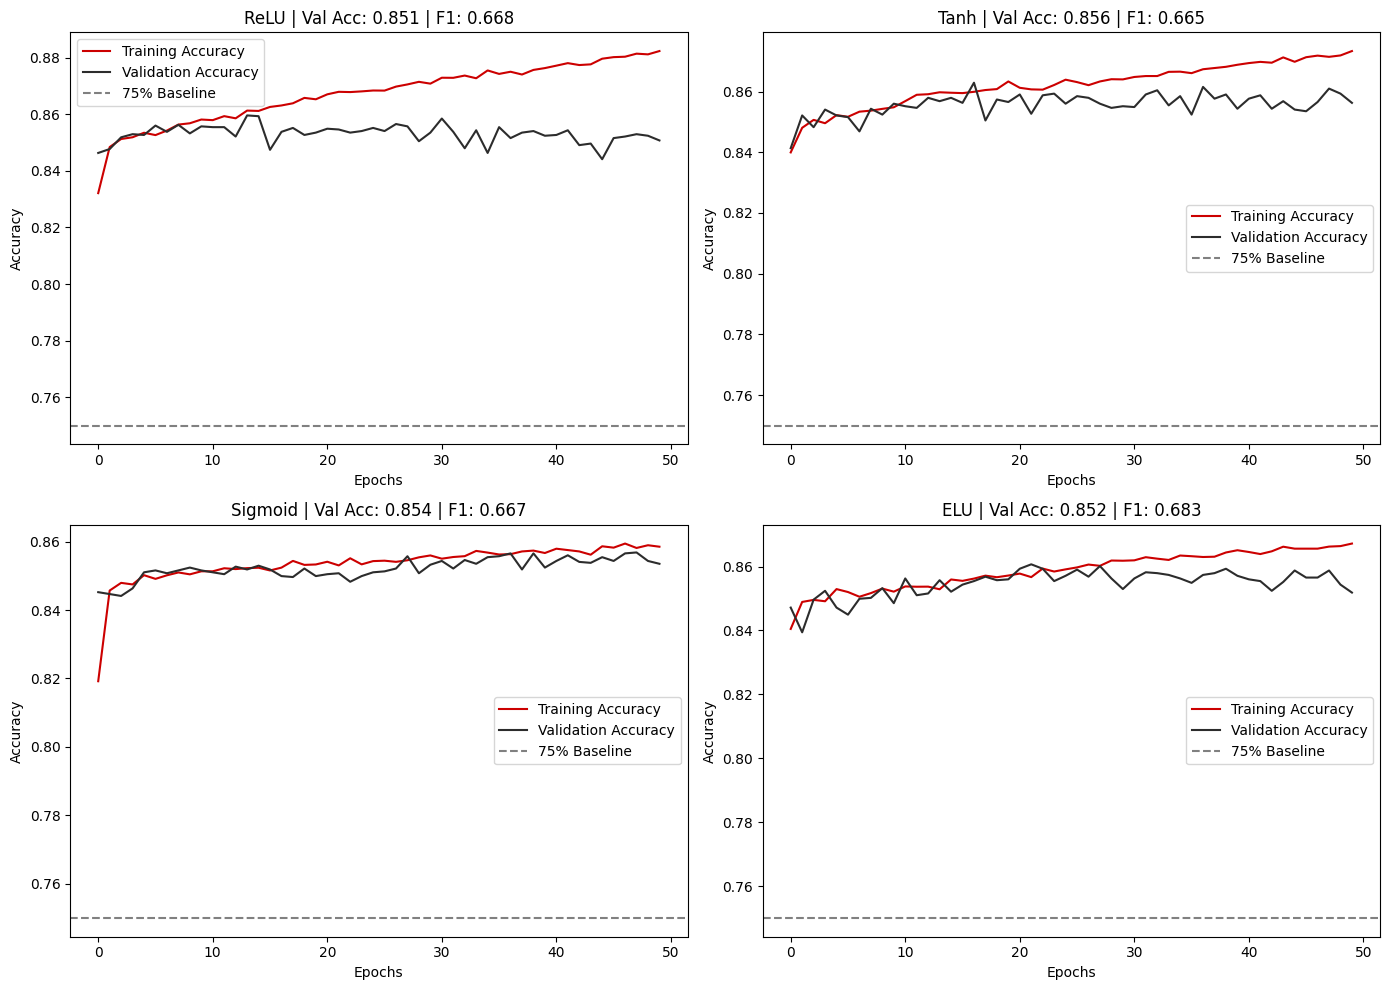

In [162]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

histories = [history_relu, history_tanh, history_sigmoid, history_elu]
f1_scores = [f1_relu, f1_tanh, f1_sigmoid, f1_elu]
names = ['ReLU', 'Tanh', 'Sigmoid', 'ELU']

for ax, history, f1, name in zip(axes.flatten(), histories, f1_scores, names):

    ax.plot(history.history['accuracy'], color='#CC0000', label='Training Accuracy')
    ax.plot(history.history['val_accuracy'], color='#2C2C2C', label='Validation Accuracy')

    ax.axhline(y=0.75, color='gray', linestyle='--', label='75% Baseline')

    ax.set_title(f'{name} | Val Acc: {history.history["val_accuracy"][-1]:.3f} | F1: {f1:.3f}')
    ax.set_xlabel('Epochs')
    ax.set_ylabel('Accuracy')
    ax.legend()

plt.tight_layout()
plt.show()

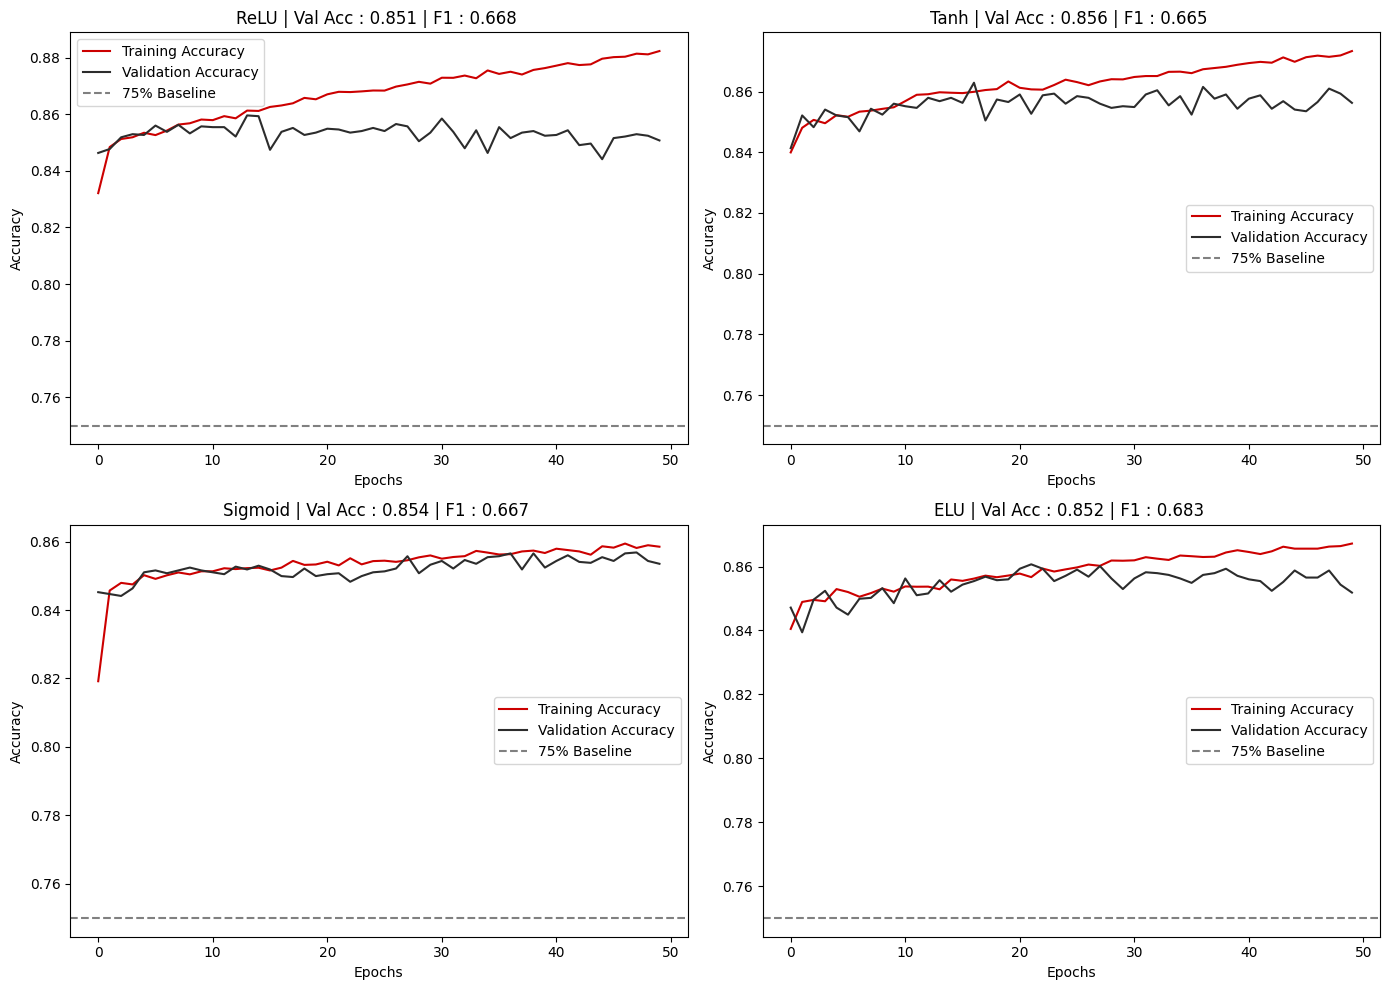

In [177]:
plt.figure(figsize=(14, 10))

plt.subplot(2,2,1)
plt.plot(history_relu.history['accuracy'], color='#CC0000', label='Training Accuracy')
plt.plot(history_relu.history['val_accuracy'], color='#2C2C2C', label='Validation Accuracy')
plt.axhline(y=0.75, color='gray', linestyle='--', label='75% Baseline')
plt.title(f'ReLU | Val Acc : {history_relu.history["val_accuracy"][-1]:.3f} | F1 : {f1_relu:.3f} ')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(2,2,2)
plt.plot(history_tanh.history['accuracy'], color='#CC0000', label='Training Accuracy')
plt.plot(history_tanh.history['val_accuracy'], color='#2C2C2C', label='Validation Accuracy')
plt.axhline(y=0.75, color='gray', linestyle='--', label='75% Baseline')
plt.title(f'Tanh | Val Acc : {history_tanh.history["val_accuracy"][-1]:.3f} | F1 : {f1_tanh:.3f} ')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(2,2,3)
plt.plot(history_sigmoid.history['accuracy'], color='#CC0000', label='Training Accuracy')
plt.plot(history_sigmoid.history['val_accuracy'], color='#2C2C2C', label='Validation Accuracy')
plt.axhline(y=0.75, color='gray', linestyle='--', label='75% Baseline')
plt.title(f'Sigmoid | Val Acc : {history_sigmoid.history["val_accuracy"][-1]:.3f} | F1 : {f1_sigmoid:.3f} ')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(2,2,4)
plt.plot(history_elu.history['accuracy'], color='#CC0000', label='Training Accuracy')
plt.plot(history_elu.history['val_accuracy'], color='#2C2C2C', label='Validation Accuracy')
plt.axhline(y=0.75, color='gray', linestyle='--', label='75% Baseline')
plt.title(f'ELU | Val Acc : {history_elu.history["val_accuracy"][-1]:.3f} | F1 : {f1_elu:.3f} ')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

---------------------------------------------------------------------------------------------------------------------------------------------------

### Task 4: Weight Initialization Techniques

4.1 Train 5 models with different initialisers

In [182]:
model_glorot_uniform = build_ann( input_dim=X_train.shape[1], activation='relu', initializer='glorot_uniform' )

history_glorot_uniform = model_glorot_uniform.fit( X_train, y_train, epochs=50, batch_size=64, validation_split=0.1, verbose=1 )

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 993us/step - accuracy: 0.8384 - loss: 0.3443 - val_accuracy: 0.8527 - val_loss: 0.3259
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 832us/step - accuracy: 0.8502 - loss: 0.3208 - val_accuracy: 0.8496 - val_loss: 0.3319
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 890us/step - accuracy: 0.8520 - loss: 0.3175 - val_accuracy: 0.8491 - val_loss: 0.3250
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 920us/step - accuracy: 0.8539 - loss: 0.3134 - val_accuracy: 0.8502 - val_loss: 0.3225
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 900us/step - accuracy: 0.8535 - loss: 0.3120 - val_accuracy: 0.8485 - val_loss: 0.3291
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 927us/step - accuracy: 0.8548 - loss: 0.3091 - val_accuracy: 0.8554 - val_loss: 0.3198
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 930us/step - accuracy: 0.8562 - loss: 0.3075 - val_accuracy: 0.8554 - val_loss: 0.3199
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 923us/step - accuracy: 0.8567 - loss: 0.3049 - 

In [183]:
model_glorot_normal = build_ann( input_dim=X_train.shape[1], activation='relu', initializer='glorot_normal')

history_glorot_normal = model_glorot_normal.fit( X_train, y_train, epochs=50, batch_size=64, validation_split=0.1, verbose=1)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 998us/step - accuracy: 0.8332 - loss: 0.3557 - val_accuracy: 0.8527 - val_loss: 0.3265
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 838us/step - accuracy: 0.8494 - loss: 0.3200 - val_accuracy: 0.8519 - val_loss: 0.3254
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 827us/step - accuracy: 0.8515 - loss: 0.3168 - val_accuracy: 0.8541 - val_loss: 0.3220
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 902us/step - accuracy: 0.8525 - loss: 0.3148 - val_accuracy: 0.8524 - val_loss: 0.3197
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 912us/step - accuracy: 0.8547 - loss: 0.3113 - val_accuracy: 0.8541 - val_loss: 0.3199
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 913us/step - accuracy: 0.8540 - loss: 0.3094 - val_accuracy: 0.8571 - val_loss: 0.3180
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 925us/step - accuracy: 0.8554 - loss: 0.3076 - val_accuracy: 0.8510 - val_loss: 0.3232
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 888us/step - accuracy: 0.8568 - loss: 0.3051 - 

In [184]:
model_glorot_he_uniform = build_ann( input_dim=X_train.shape[1], activation='relu', initializer='he_uniform')

history_glorot_he_uniform = model_glorot_he_uniform.fit( X_train, y_train, epochs=50, batch_size=64, validation_split=0.1, verbose=1)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8366 - loss: 0.3530 - val_accuracy: 0.8491 - val_loss: 0.3256
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 846us/step - accuracy: 0.8469 - loss: 0.3246 - val_accuracy: 0.8402 - val_loss: 0.3375
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 838us/step - accuracy: 0.8482 - loss: 0.3190 - val_accuracy: 0.8552 - val_loss: 0.3192
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 831us/step - accuracy: 0.8515 - loss: 0.3163 - val_accuracy: 0.8488 - val_loss: 0.3248
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 901us/step - accuracy: 0.8529 - loss: 0.3139 - val_accuracy: 0.8463 - val_loss: 0.3284
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 910us/step - accuracy: 0.8535 - loss: 0.3104 - val_accuracy: 0.8491 - val_loss: 0.3263
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 901us/step - accuracy: 0.8553 - loss: 0.3085 - val_accuracy: 0.8557 - val_loss: 0.3158
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 911us/step - accuracy: 0.8573 - loss: 0.3054 - va

In [185]:
model_glorot_he_normal = build_ann( input_dim=X_train.shape[1], activation='relu', initializer='he_normal')

history_glorot_he_normal = model_glorot_he_normal.fit( X_train, y_train, epochs=50, batch_size=64, validation_split=0.1, verbose=1)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 986us/step - accuracy: 0.8422 - loss: 0.3419 - val_accuracy: 0.8422 - val_loss: 0.3397
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 823us/step - accuracy: 0.8505 - loss: 0.3209 - val_accuracy: 0.8535 - val_loss: 0.3224
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 828us/step - accuracy: 0.8508 - loss: 0.3180 - val_accuracy: 0.8519 - val_loss: 0.3209
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 825us/step - accuracy: 0.8528 - loss: 0.3146 - val_accuracy: 0.8532 - val_loss: 0.3178
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 957us/step - accuracy: 0.8550 - loss: 0.3112 - val_accuracy: 0.8524 - val_loss: 0.3221
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 927us/step - accuracy: 0.8548 - loss: 0.3084 - val_accuracy: 0.8563 - val_loss: 0.3174
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 915us/step - accuracy: 0.8547 - loss: 0.3071 - val_accuracy: 0.8552 - val_loss: 0.3193
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 903us/step - accuracy: 0.8567 - loss: 0.3054 - 

In [186]:
model_zeros = build_ann( input_dim=X_train.shape[1], activation='relu', initializer='zeros' )

history_zeros = model_zeros.fit(X_train, y_train, epochs=50, batch_size=64, validation_split=0.1, verbose=1)

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 995us/step - accuracy: 0.7521 - loss: 0.6448 - val_accuracy: 0.7526 - val_loss: 0.6074
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 822us/step - accuracy: 0.7521 - loss: 0.5878 - val_accuracy: 0.7526 - val_loss: 0.5732
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 833us/step - accuracy: 0.7521 - loss: 0.5671 - val_accuracy: 0.7526 - val_loss: 0.5624
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 828us/step - accuracy: 0.7521 - loss: 0.5614 - val_accuracy: 0.7526 - val_loss: 0.5600
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 830us/step - accuracy: 0.7521 - loss: 0.5602 - val_accuracy: 0.7526 - val_loss: 0.5595
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 857us/step - accuracy: 0.7521 - loss: 0.5600 - val_accuracy: 0.7526 - val_loss: 0.5594
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 868us/step - accuracy: 0.7521 - loss: 0.5600 - val_accuracy: 0.7526 - val_loss: 0.5594
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 833us/step - accuracy: 0.7521 - loss: 0.5600 - 

4.3 Convergence speed comparison plot

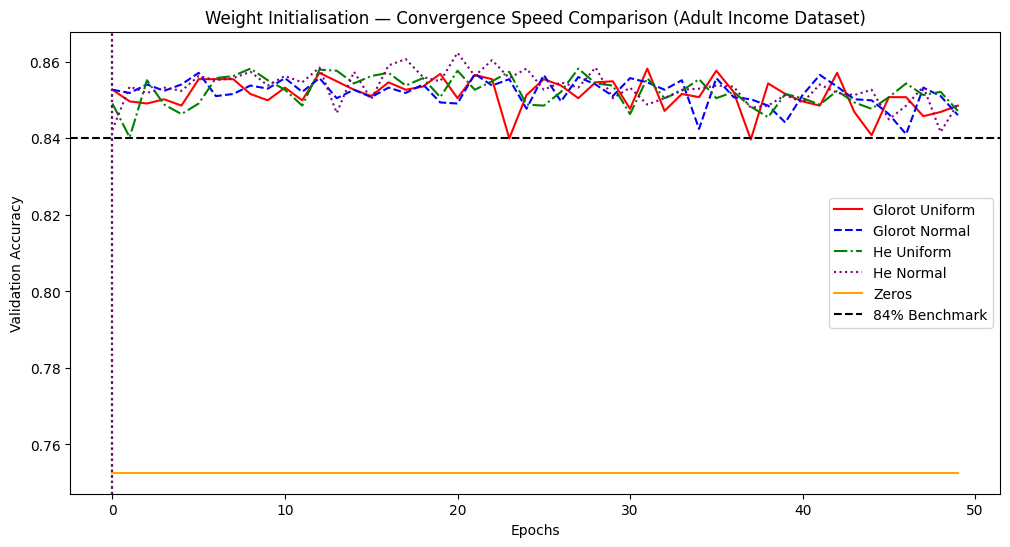

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(history_glorot_uniform.history['val_accuracy'], color='red', linestyle='-', label='Glorot Uniform')
plt.plot(history_glorot_normal.history['val_accuracy'], color='blue', linestyle='--', label='Glorot Normal')
plt.plot(history_glorot_he_uniform.history['val_accuracy'], color='green', linestyle='-.', label='He Uniform')
plt.plot(history_glorot_he_normal.history['val_accuracy'], color='purple', linestyle=':', label='He Normal')
plt.plot(history_zeros.history['val_accuracy'], color='orange', linestyle='-', label='Zeros')

plt.axhline(y=0.84, color='black', linestyle='--', label='84% Benchmark')

plt.axvline(x=np.argmax(np.array(history_glorot_uniform.history['val_accuracy']) >= 0.82), color='red', linestyle=':')
plt.axvline(x=np.argmax(np.array(history_glorot_normal.history['val_accuracy']) >= 0.82), color='blue', linestyle=':')
plt.axvline(x=np.argmax(np.array(history_glorot_he_uniform.history['val_accuracy']) >= 0.82), color='green', linestyle=':')
plt.axvline(x=np.argmax(np.array(history_glorot_he_normal.history['val_accuracy']) >= 0.82), color='purple', linestyle=':')

plt.title('Weight Initialisation — Convergence Speed Comparison (Adult Income Dataset)')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.show()

4.4 Zeros failure demonstration

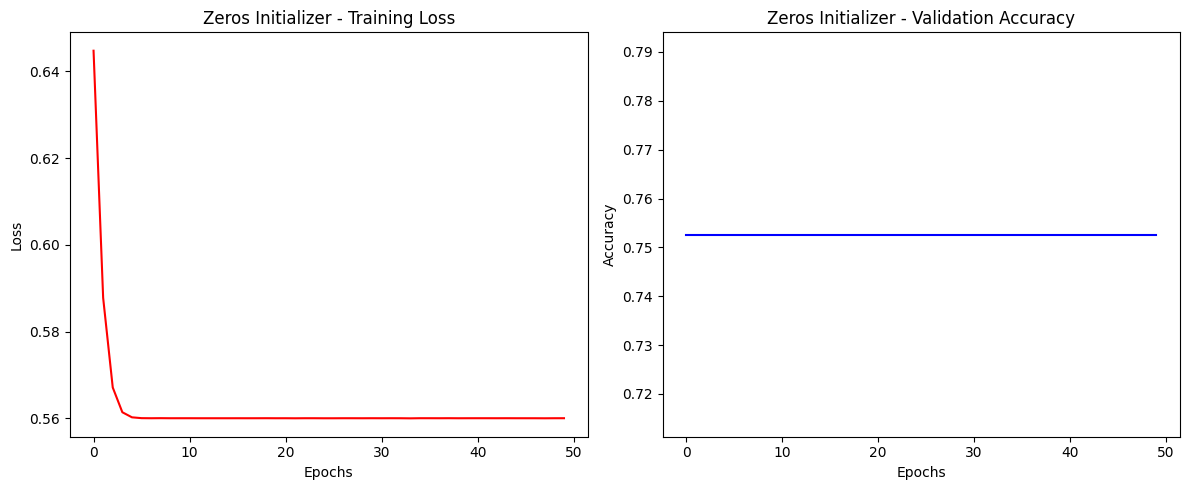

In [193]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_zeros.history['loss'], color='red')
plt.title('Zeros Initializer - Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.subplot(1, 2, 2)
plt.plot(history_zeros.history['val_accuracy'], color='blue')
plt.title('Zeros Initializer - Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.tight_layout()
plt.show()

---------------------------------------------------------------------------------------------------------------------------------------------------

### Task 5: Loss Functions

5.2 MSE as classification loss — wrong tool experiment

In [194]:
model_mse = build_ann( input_dim=X_train.shape[1], loss='mean_squared_error', activation='relu', initializer='he_normal' )

history_mse = model_mse.fit(X_train, y_train, epochs=50, batch_size=64, validation_split=0.1, verbose=1 )

Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 1s 993us/step - accuracy: 0.8294 - loss: 0.1211 - val_accuracy: 0.8488 - val_loss: 0.1052
Epoch 2/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 816us/step - accuracy: 0.8498 - loss: 0.1032 - val_accuracy: 0.8505 - val_loss: 0.1045
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 817us/step - accuracy: 0.8512 - loss: 0.1024 - val_accuracy: 0.8546 - val_loss: 0.1033
Epoch 4/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 825us/step - accuracy: 0.8540 - loss: 0.1013 - val_accuracy: 0.8519 - val_loss: 0.1059
Epoch 5/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 816us/step - accuracy: 0.8545 - loss: 0.1007 - val_accuracy: 0.8524 - val_loss: 0.1053
Epoch 6/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 823us/step - accuracy: 0.8556 - loss: 0.0998 - val_accuracy: 0.8527 - val_loss: 0.1045
Epoch 7/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 819us/step - accuracy: 0.8552 - loss: 0.0993 - val_accuracy: 0.8560 - val_loss: 0.1022
Epoch 8/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 832us/step - accuracy: 0.8576 - loss: 0.0986 - 

In [195]:
y_pred_base = (model_base.predict(X_test).flatten() > 0.5).astype(int)
y_pred_mse = (model_mse.predict(X_test).flatten() > 0.5).astype(int)

f1_base = metrics.f1_score(y_test, y_pred_base)
f1_mse = metrics.f1_score(y_test, y_pred_mse)

print("Baseline F1-score:", f1_base)
print("MSE F1-score:", f1_mse)

283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 462us/step
283/283 ━━━━━━━━━━━━━━━━━━━━ 0s 482us/step
Baseline F1-score: 0.6612087647483746
MSE F1-score: 0.6649012999518537


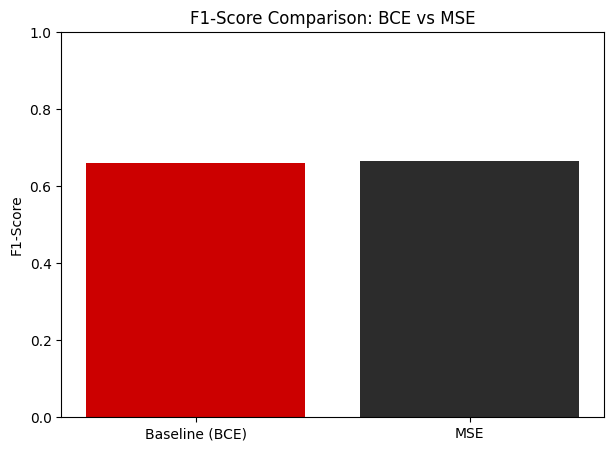

In [200]:
plt.figure(figsize=(7, 5))

plt.bar(['Baseline (BCE)', 'MSE'], [f1_base, f1_mse], color=['#CC0000', '#2C2C2C'])

plt.title('F1-Score Comparison: BCE vs MSE')
plt.ylabel('F1-Score')
plt.ylim(0, 1)

plt.show()